# (G)VAR extensions: nonlinearity and exogenous inputs

Comparison of every (G)VAR variant on `cave_proofread` (session 4_7). Same chronological split, normalisation, test windows and metrics for all models: a 15-frame context, then a recursive 5-step forecast. MSE is in standardised log1p units.

Selection uses the validation MSE averaged over horizons 1..5, so choices favour models that forecast well recursively. P=15, K=3 throughout: the P x K grid selects it under both one-step and five-step validation.

In [1]:
import copy, shutil, sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parents[1]))  # repository root, for models.VAR
from data import load_data
from train import run, evaluate, eval_windows, CONTEXT
from gvar import GVAR
import gvar_nonlinear
from models.VAR import train_varx

EXO = dict(video_pcs=32, behaviour=('treadmill',))
data = load_data('cave_proofread')
data_x = load_data('cave_proofread', **EXO)
print('activity', tuple(data['X'].shape), ' exogenous', tuple(data_x['U'].shape),
      f" (32 video PCs explain {sum(data_x['video_explained']):.0%} of pixel variance, + treadmill)")
print('nonlinear models train on', gvar_nonlinear.device())

BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
INK, GRAY = '#52514e', '#a3a29b'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e6e5e0', 'grid.linewidth': 0.8, 'lines.linewidth': 2, 'figure.dpi': 110,
                     'axes.edgecolor': GRAY, 'axes.labelcolor': INK, 'xtick.color': INK, 'ytick.color': INK})
results = {}  # name -> {'test': metrics, 'params': int}

activity (37840, 1059)  exogenous (37840, 33)  (32 video PCs explain 71% of pixel variance, + treadmill)
nonlinear models train on cuda


## 1. Population VAR and VAR-X

VAR(1) learns a dense N x N matrix plus intercepts (Baturalp's model). VAR-X adds a per-neuron readout of the lagged exogenous inputs $[\mathbf{u}_t, \dots, \mathbf{u}_{t-Q+1}]$ with its own ridge penalty:
- video: 32 PCA components of the stimulus frame, fitted on training frames. The stimulus is designed in advance, so future frames are known.
- treadmill speed: lagged one frame and held at its last value during a forecast, since it is not known in advance.

Pupil is left out because it has NaNs in 16% of rows.

In [2]:
def var_run(name, **kw):
    out = Path('../VAR/runs') / name
    shutil.rmtree(out, ignore_errors=True)
    model, res, _ = train_varx.run('cave_proofread', out, verbose=False, **kw)
    results[name] = {'test': res['test']['varx'], 'params': res['parameter_count']}
    print(f"{name}: Q={res['Q']} lam={res['lam']:g} lam_exo={res['lam_exo']:g}")
    return res

var_res = var_run('VAR')
varx_res = var_run('VAR-X', **EXO)
results['copy-last'] = {'test': var_res['test']['copy_last'], 'params': 0}
results['mean'] = {'test': var_res['test']['mean'], 'params': 0}

VAR: Q=1 lam=0.1 lam_exo=1
VAR-X: Q=1 lam=0.1 lam_exo=1


## 2. G-VAR and Leaky G-VAR

G-VAR shares $(K+1)P = 64$ graph-filter taps across all neurons: $\mathbf{x}_t = \sum_{k,p} h_{kp}\,\mathbf{S}^k\mathbf{x}_{t-p}$.

Leaky G-VAR adds taps on $\mathbf{S}^k\,\mathrm{relu}(\mathbf{x}_{t-p})$, a LeakyReLU of the inputs with a learned slope per tap. The nonlinearity acts before the graph filter, so the model is still linear in its parameters and is fitted in closed form. It is nonlinear in the inputs, but only additively, with one kink.

In [3]:
def gvar_run(name, d=data, **cfg):
    model, res = run({'P': 15, 'K': 3, **cfg}, data=d, verbose=False)
    results[name] = {'test': res['test']['gvar'], 'params': res['parameter_count']}
    return model, res

gvar_run('G-VAR', clamp=False, intercept=False)
gvar_run('Leaky G-VAR', clamp=False, intercept=False, leaky=True)
pd.DataFrame({n: results[n]['test']['mse'] for n in ('G-VAR', 'Leaky G-VAR')}, index=range(1, 6)).T.round(4)

,1,2,3,4,5
G-VAR,0.4288,0.7131,0.7285,0.7318,0.7337
Leaky G-VAR,0.4170,0.7391,0.8396,0.9228,0.9308


Leaky inputs help at h=1 but hurt the recursive forecast badly.

## 3. Clamp and intercept

- **Clamp**: each forecast step is clamped at the neuron's lowest training value before it is fed back. About 79% of all entries sit exactly at that floor (raw activity 0), and activity cannot go lower.
- **Intercept**: an unpenalised constant per neuron. Without one, the silent-regime slope has to stand in for a baseline.

In [4]:
gvar_cl, _ = gvar_run('G-VAR + clamp + intercept')
leaky_cl, _ = gvar_run('Leaky G-VAR + clamp + intercept', leaky=True)
pd.DataFrame({n: results[n]['test']['mse'] for n in ('G-VAR + clamp + intercept', 'Leaky G-VAR + clamp + intercept')},
             index=range(1, 6)).T.round(4)

,1,2,3,4,5
G-VAR + clamp + intercept,0.4216,0.7138,0.7280,0.7314,0.7333
Leaky G-VAR + clamp + intercept,0.4093,0.7354,0.8486,0.9535,0.9776


Both give a small gain at h=1, but neither fixes the leaky drift. The reason: for a silent neuron the one-step forecast is slightly above the floor, an average of "stays silent" and "starts firing". Fed back as an input, that value looks like the onset of activity, and the steep silent-regime slope amplifies it.

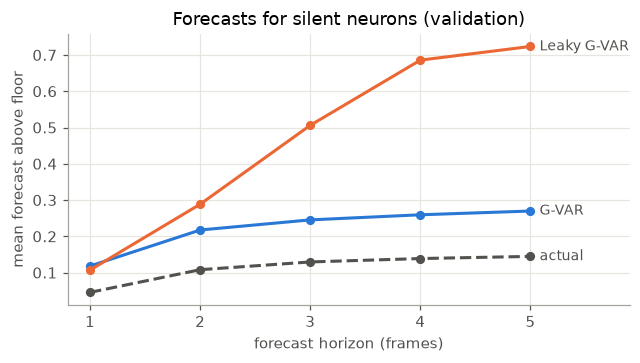

In [5]:
# Neurons silent through the whole 15-frame context: how far above the floor are the forecasts?
xw, _ = eval_windows(data, 'val', 5)
past, target = xw[:, :CONTEXT], xw[:, CONTEXT:]
floor = data['floor']
silent = (past <= floor + 1e-4).all(1)  # [windows, neurons]
above = lambda p: [(p[:, j] - floor)[silent].mean().item() for j in range(5)]
drift = {'actual': above(target)}
for name, m in (('G-VAR', gvar_cl), ('Leaky G-VAR', leaky_cl)):
    drift[name] = above(torch.cat([m.rollout(b, 5) for b in past.split(2048)]))

hs = np.arange(1, 6)
fig, ax = plt.subplots(figsize=(6, 3.4))
for (name, v), color, style in zip(drift.items(), (INK, BLUE, ORANGE), ('--', '-', '-')):
    ax.plot(hs, v, style, color=color, marker='o', markersize=5)
    ax.annotate(name, (5, v[-1]), xytext=(6, 0), textcoords='offset points', va='center', color=INK, fontsize=9)
ax.set(xlabel='forecast horizon (frames)', ylabel='mean forecast above floor',
       title='Forecasts for silent neurons (validation)', xticks=hs, xlim=(0.8, 5.9))
plt.tight_layout()
plt.show()

## 4. G-VAR-X

The G-VAR with the same exogenous inputs as VAR-X. The taps $h$ stay shared, and each neuron gets its own readout $\mathbf{B}$ of the lagged inputs. $\mathbf{B}$ is eliminated per neuron in closed form, which leaves a 64-dimensional system for the taps. Q and the exogenous penalty are selected on validation.

In [6]:
gvarx_cl, gvarx_res = gvar_run('G-VAR-X', d=data_x)
print(f"selected Q={gvarx_res['Q']}, lam_exo={gvarx_res['lam_exo']:g}")

selected Q=1, lam_exo=1


## 5. Nonlinear G-VAR and G-VAR-X

Stacked graph filters with ReLUs between them, on top of the frozen G-VAR(-X) above:

$$\mathbf{H}^{l} = \mathrm{relu}\Big(\sum_k \mathbf{S}^k \mathbf{H}^{l-1} \mathbf{W}^l_k + \mathbf{b}^l\Big), \qquad \hat{\mathbf{x}}_t = \text{G-VAR}(\cdot) + \sum_k \mathbf{S}^k \mathbf{H}^L \mathbf{w}_k$$

Here $\mathbf{H}^0$ holds each node's 15 lags, plus a learned projection of the exogenous lags for G-VAR-X. There are 2 layers of 32 channels with K=3, trained with Adam on the one-step loss. The readout starts at zero, so epoch 0 is the G-VAR(-X).

Stopped on the five-step validation score, both models keep epoch 0, i.e. they reduce to the linear model. They are stopped on **one-step** validation here instead, to show what the nonlinearity buys and costs.

In [7]:
def nonlinear(name, linear, d, epochs=15):
    val = eval_windows(d, 'val', 5)
    def score(m):
        mse = evaluate(m, val, 5, d['known_ahead'])['gvar']['mse']
        return {'val_mse': mse[0], 'val_mse_h1': mse[0], 'val_avg': sum(mse) / 5}  # stop on h=1
    model = gvar_nonlinear.NonlinearGVAR(copy.deepcopy(linear)).to(gvar_nonlinear.device())
    model, history, best = gvar_nonlinear.train(model, d, score, epochs=epochs, verbose=False)
    test = evaluate(model, eval_windows(d, 'test', 5), 5, d['known_ahead'])['gvar']
    results[name] = {'test': test, 'params': linear.parameter_count + model.parameter_count}
    print(f'{name}: best epoch {best}, {model.parameter_count} network parameters')
    return pd.DataFrame(history)

hist = {'Nonlinear G-VAR': nonlinear('Nonlinear G-VAR', gvar_cl, data),
        'Nonlinear G-VAR-X': nonlinear('Nonlinear G-VAR-X', gvarx_cl, data_x)}

Nonlinear G-VAR: best epoch 15, 6209 network parameters
Nonlinear G-VAR-X: best epoch 15, 7505 network parameters


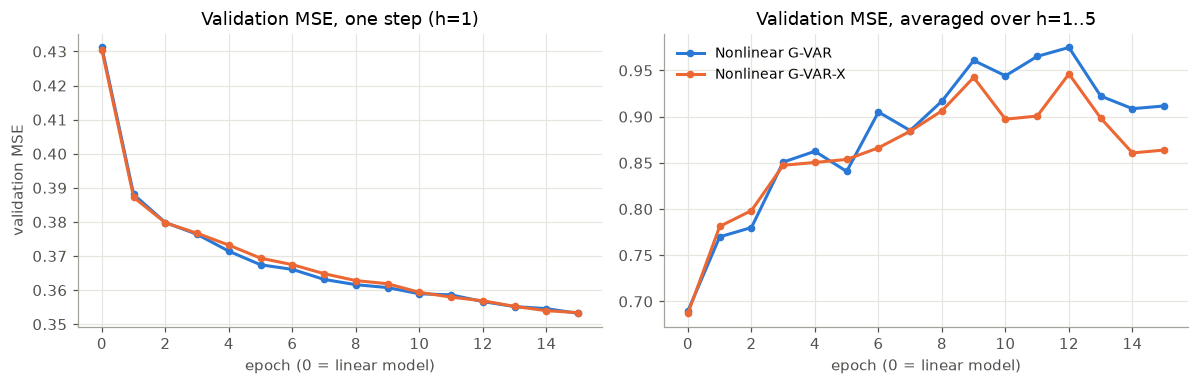

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, col, title in zip(axes, ('val_mse_h1', 'val_avg'), ('one step (h=1)', 'averaged over h=1..5')):
    for (name, h), color in zip(hist.items(), (BLUE, ORANGE)):
        ax.plot(h['epoch'], h[col], color=color, marker='o', markersize=4, label=name)
    ax.set(xlabel='epoch (0 = linear model)', title=f'Validation MSE, {title}')
axes[0].set_ylabel('validation MSE')
axes[1].legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

One-step error keeps falling until the 15-epoch cap, while the five-step error rises from the first epoch on: the same rollout drift as the leaky model, but stronger.

## 6. All models

In [1]:
order = ['mean', 'copy-last', 'VAR', 'VAR-X', 'G-VAR', 'Leaky G-VAR', 'G-VAR + clamp + intercept',
         'Leaky G-VAR + clamp + intercept', 'G-VAR-X', 'Nonlinear G-VAR', 'Nonlinear G-VAR-X']
table = pd.DataFrame({n: {'parameters': results[n]['params'],
                          **{f'MSE h={h}': results[n]['test']['mse'][h - 1] for h in range(1, 6)},
                          'MSE avg': np.mean(results[n]['test']['mse']),
                          'Pearson h=1': results[n]['test']['pearson'][0],
                          'Pearson h=5': results[n]['test']['pearson'][4]} for n in order}).T
table['parameters'] = table['parameters'].astype(int)
table.style.format({c: '{:.4f}' for c in table.columns if c != 'parameters'} | {'parameters': '{:,}'}) \
    .highlight_min(subset=[c for c in table.columns if c.startswith('MSE')], color='#d7e6f8')

NameError: name 'pd' is not defined

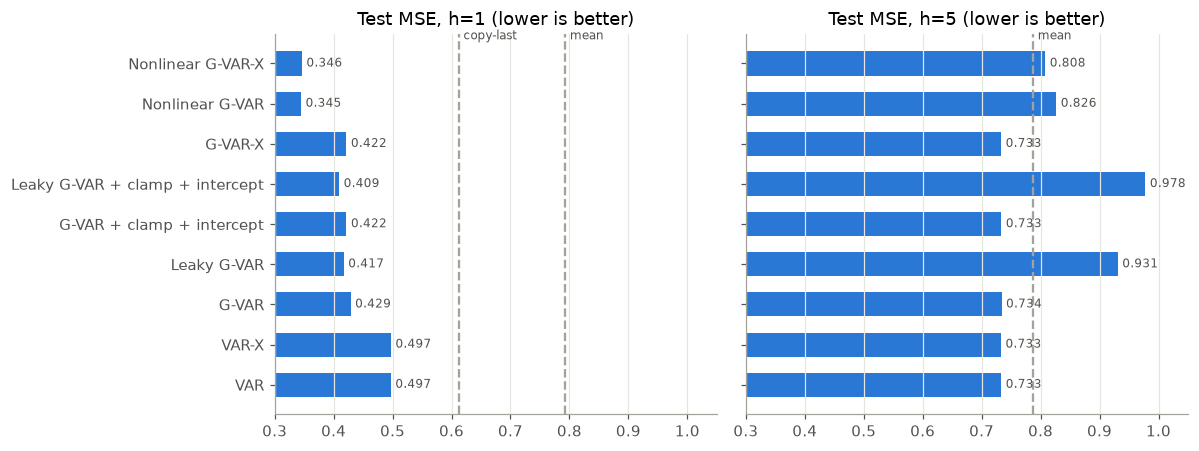

In [ ]:
models = [n for n in order if n not in ('mean', 'copy-last')]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
axes[0].invert_yaxis()  # once: the y axis is shared
for ax, h in zip(axes, (1, 5)):
    v = [results[n]['test']['mse'][h - 1] for n in models]
    y = np.arange(len(models))
    ax.barh(y, v, height=0.6, color=BLUE)
    for b in ('copy-last', 'mean'):
        ref = results[b]['test']['mse'][h - 1]
        if ref < 1.0:
            ax.axvline(ref, color=GRAY, linestyle='--', linewidth=1.5)
            ax.annotate(b, (ref, len(models) - 0.4), xytext=(3, 0), textcoords='offset points', color=INK, fontsize=8)
    for yi, vi in zip(y, v):
        ax.annotate(f'{vi:.3f}', (vi, yi), xytext=(3, 0), textcoords='offset points', va='center', color=INK, fontsize=8,
                    bbox=dict(facecolor='white', edgecolor='none', pad=0.5))
    ax.set(title=f'Test MSE, h={h} (lower is better)', yticks=y, yticklabels=models, xlim=(0.3, 1.05))
    ax.grid(axis='y', visible=False)
    ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

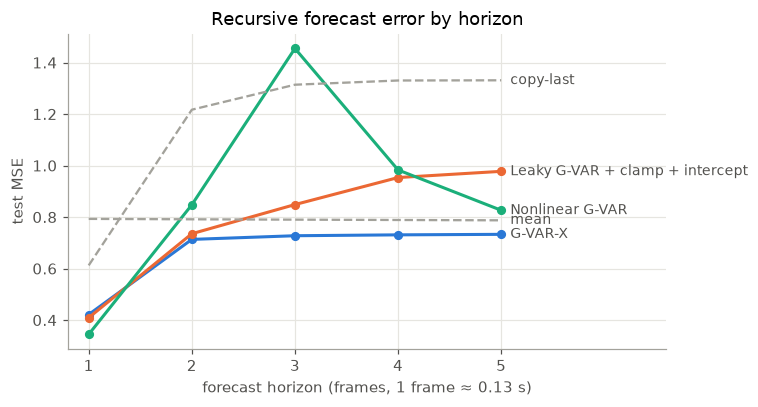

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.8))
lines = [('G-VAR-X', BLUE, '-'), ('Leaky G-VAR + clamp + intercept', ORANGE, '-'), ('Nonlinear G-VAR', AQUA, '-'),
         ('copy-last', GRAY, '--'), ('mean', GRAY, '--')]
for name, color, style in lines:
    ax.plot(hs, results[name]['test']['mse'], style, color=color, marker='o' if style == '-' else None, markersize=5,
            linewidth=2 if style == '-' else 1.5)
# end labels, spread apart so close lines do not collide
ends = sorted((results[n]['test']['mse'][-1], n) for n, _, _ in lines)
y_prev = -np.inf
for y, name in ends:
    y_prev = max(y, y_prev + 0.07)
    ax.annotate(name, (5, y), xytext=(5.12, y_prev), textcoords='data', va='center', color=INK, fontsize=9)
ax.set(xlabel='forecast horizon (frames, 1 frame ≈ 0.13 s)', ylabel='test MSE', xticks=hs, xlim=(0.8, 6.6),
       title='Recursive forecast error by horizon')
plt.tight_layout()
plt.show()

## Takeaways

- **Linear models are the best recursive forecasters, and they are close.** G-VAR-X has the lowest MSE averaged over h=1..5 (0.665), but its advantage is all at h=1 (0.422 vs 0.497 for VAR). From h=2 on, VAR and VAR-X are slightly better, and at h≥3 all linear models are within about 0.005. The exogenous inputs change little: 32 pixel PCs and treadmill speed explain about 1% of the variance on their own.
- **Nonlinearity buys one-step accuracy and costs multi-step accuracy.** The nonlinear graph network reaches h=1 MSE 0.345 (18% below G-VAR, Pearson 0.74), but at h=3 its error (1.45) exceeds copy-last. Leaky inputs show the same pattern, more mildly. Silent neurons dominate the data, and their averaged forecasts look like activity onsets once fed back.
- **Clamp and intercept** give a small gain to linear G-VAR at every horizon. They do not fix the leaky drift.
- With five-step selection, every nonlinear variant falls back to its linear model. Avoiding the drift would need multi-step training (e.g. scheduled sampling, as in DCRNN), which this protocol does not use.